## Router Working (Conditionsal)

In [11]:

from langchain_openai import ChatOpenAI
from dotenv import load_dotenv
from langchain_core.tools import tool
from langchain_core.messages import AIMessage, HumanMessage, ToolMessage, SystemMessage
import os

load_dotenv()

if os.environ['OPENAI_API_KEY']:
    print("Openai key is set")
else:
    raise ValueError("openAi key is not set")


llm_openai = ChatOpenAI(model='gpt-5-mini',temperature=0)




Openai key is set


In [12]:
from pydantic import BaseModel, Field
from typing import Literal

class llm_schema (BaseModel):
    category: Literal['insta', 'Youtube', 'linkedin'] = Field(..., description="Category of the post to generate")
    topic: str = Field(..., description="Topic of the post to generate")

llm_openai_schema=llm_openai.with_structured_output(llm_schema)
llm_openai_schema.invoke("Give me post for youtube")

llm_schema(category='Youtube', topic='Title: How I Grew from 0 to 100k Subscribers in 12 Months (Step-by-Step) \n\nDescription: In this video I break down the exact strategy I used to grow from zero to 100,000 subscribers in one year — no viral luck, just repeatable systems. I cover niche selection, content planning, thumbnails, SEO, collaboration tactics, and the daily habits that made it possible. If you want a clear, actionable roadmap for growing your channel, watch till the end and download the free checklist in the description. \n\nTags: YouTube growth, channel growth, grow on YouTube, YouTube tips, content strategy, thumbnails, YouTube SEO, audience retention, creator tips, how to get subscribers \n\nScript Outline (90–120 seconds hook + 6–8 minute video):\n1) Hook (0:00–0:20): "I started this channel with zero subscribers — one year later I hit 100,000. No viral video, just a system. In the next 10 minutes I’ll show you exactly what I did so you can copy it."\n2) Quick credibil

In [13]:
from typing import TypedDict, List
class graph_schema(TypedDict):
    input: str
    topic: str
    post: str
    category: str


## Router Node ##


In [14]:
def router_node(state:graph_schema)-> graph_schema:
    user_input = state['input']
    response = llm_openai_schema.invoke(user_input)
    category = response.category
    topic = response.topic 
    state['category']=category
    state['topic']=topic
    return state

## Create nodes ##

In [15]:
def create_post_insta(state:graph_schema) -> graph_schema:
    topic = state['topic']
    post = llm_openai.invoke(f"Write an Instagram post about {topic}. Keep the tone casual and engaging.").content
    state['post']= post
    return {'post':post}


def create_post_link(state:graph_schema) -> graph_schema:
    topic = state['topic']
    post = llm_openai.invoke(f"Write an Linkedin post about {topic}. Keep the tone casual and engaging.").content
    state['post']= post
    return {'post':post}

def create_post_yt(state:graph_schema) -> graph_schema:
    topic = state['topic']
    post = llm_openai.invoke(f"Write an Youtube post about {topic}. Keep the tone casual and engaging.").content
    state['post']= post
    return {'post':post}

## Create a conditions

In [16]:
def condition(state:graph_schema)-> str:
    category = state['category']
    if category == 'insta':
        return 'create_insta'
    elif category == 'Youtube':
        return 'create_youtube'
    elif category == 'linkedin':
        return 'create_linkedin'
    else:
        raise ValueError("Invalid category")


## Create State

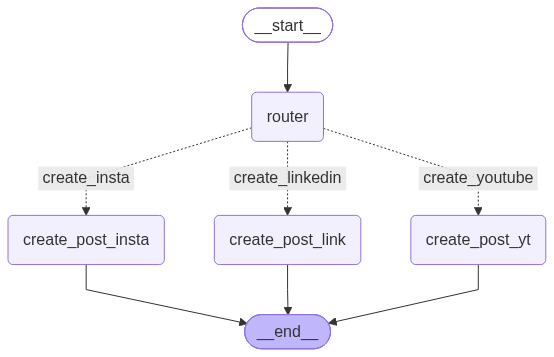

In [17]:
from langgraph.graph import StateGraph, START, END

graph = StateGraph(graph_schema)
graph.add_node('router',router_node)
graph.add_node('create_post_insta',create_post_insta)
graph.add_node('create_post_link',create_post_link)
graph.add_node('create_post_yt',create_post_yt)

graph.add_edge(START,'router')
graph.add_conditional_edges('router',condition,{
    'create_insta':"create_post_insta",
    'create_youtube':"create_post_yt",
    'create_linkedin':"create_post_link",
})

graph.add_edge('create_post_insta',END)
graph.add_edge('create_post_link',END)
graph.add_edge('create_post_yt',END)

final = graph.compile()

from IPython.display import Image, display
Image(final.get_graph().draw_mermaid_png())



In [19]:
final.invoke({
    "input": "I want to generate a post for twitter about AI",
    "topic":"",
    "category":"",
    "post":""
})

{'input': 'I want to generate a post for twitter about AI',
 'topic': 'Twitter post about AI — do you want a single tweet (≤280 characters) or a thread? Please confirm and specify tone (e.g., informative, witty, promotional).',
 'post': 'Quick question for my Twitter crowd — I’m getting ready to post about AI and want your input: do you want a single tweet (≤280 characters) or a thread? \n\nSingle tweet = punchy take. Thread = deeper dive with examples and tips. Reply with “Tweet” or “Thread” and the tone you prefer (informative, witty, promotional, practical, skeptical, etc.). Bonus: drop a topic you care about (prompt design, ethics, tools, careers).\n\nI’ll post the winner and share the tweet/thread here. Thanks — excited to co-create!',
 'category': 'linkedin'}